# QR Heston SPX and VIX smiles from simulation

We use the QRH scheme from `QRH SSR.pdf` to generate SPX and VIX smiles.


In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import integrate
import matplotlib as mpl

from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import plot_ivols_mc, var_swap_robust

sns.set_theme("talk")
mpl.rcParams["figure.figsize"] = (8, 6)

# Gamma kernel

The gamma kernel is given by $$ \kappa(\tau)= \frac{\nu}{\Gamma(\alpha)}\, \tau^{\alpha-1}\,e^{-\lambda \tau}, $$

with $\alpha = H + \tfrac12$.


In [3]:
params0 = {"al": 0.568, "lam": 9.68, "nu": 0.572, "c": 8.1e-3}

# Kernel convergence condition


We check the necessary condition $$ \int_0^\infty \kappa(s)^2 \, ds = \frac{\nu^2}{\Gamma(\alpha)^2} \frac{\Gamma(2 H)}{(2\lambda)^{2H}} < 1 $$


In [4]:
from scipy.special import gamma


def converge_test(params, opt="closed-form"):
    al = params["al"]
    H = al - 1 / 2
    lam = params["lam"]
    nu = params["nu"]

    if opt == "closed-form":
        integral = (nu / gamma(al)) ** 2 * gamma(2 * H) / (2 * lam) ** (2 * H)
    elif opt == "quad":

        def kernel(x):
            return (nu / gamma(al)) * x ** (al - 1) * np.exp(-lam * x)

        integral = integrate.quad(lambda x: kernel(x) ** 2, 0, np.inf)[0]
    else:
        raise ValueError("Check value for opt.")

    assert integral < 1
    return integral


print(converge_test(params0, opt="closed-form"))
print(converge_test(params0, opt="quad"))

0.6137021325532132
0.6137021324510988


# Initial forward variance curve $\xi_t(u)$


In [4]:
# Load market data
df_spx = pd.read_csv("spx_implied_vol_20230215.csv", index_col=0)
df_vix = pd.read_csv("vix_implied_vol_20230215.csv", index_col=0)
df_spx["Texp_days"] = (365.25 * df_spx["Texp"]).round().astype(int)
df_vix["Texp_days"] = (365.25 * df_vix["Texp"]).round().astype(int)

In [5]:
res_vs = var_swap_robust(ivol_data=df_spx)
w_in = res_vs["vs_mid"] * res_vs["expiries"]
xi_smooth = xi_curve_smooth(res_vs["expiries"], w_in, eps=0.03)["xi_curve"]

/Users/florianbourgey/projects/QuadraticRoughHeston/utils.py:183: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


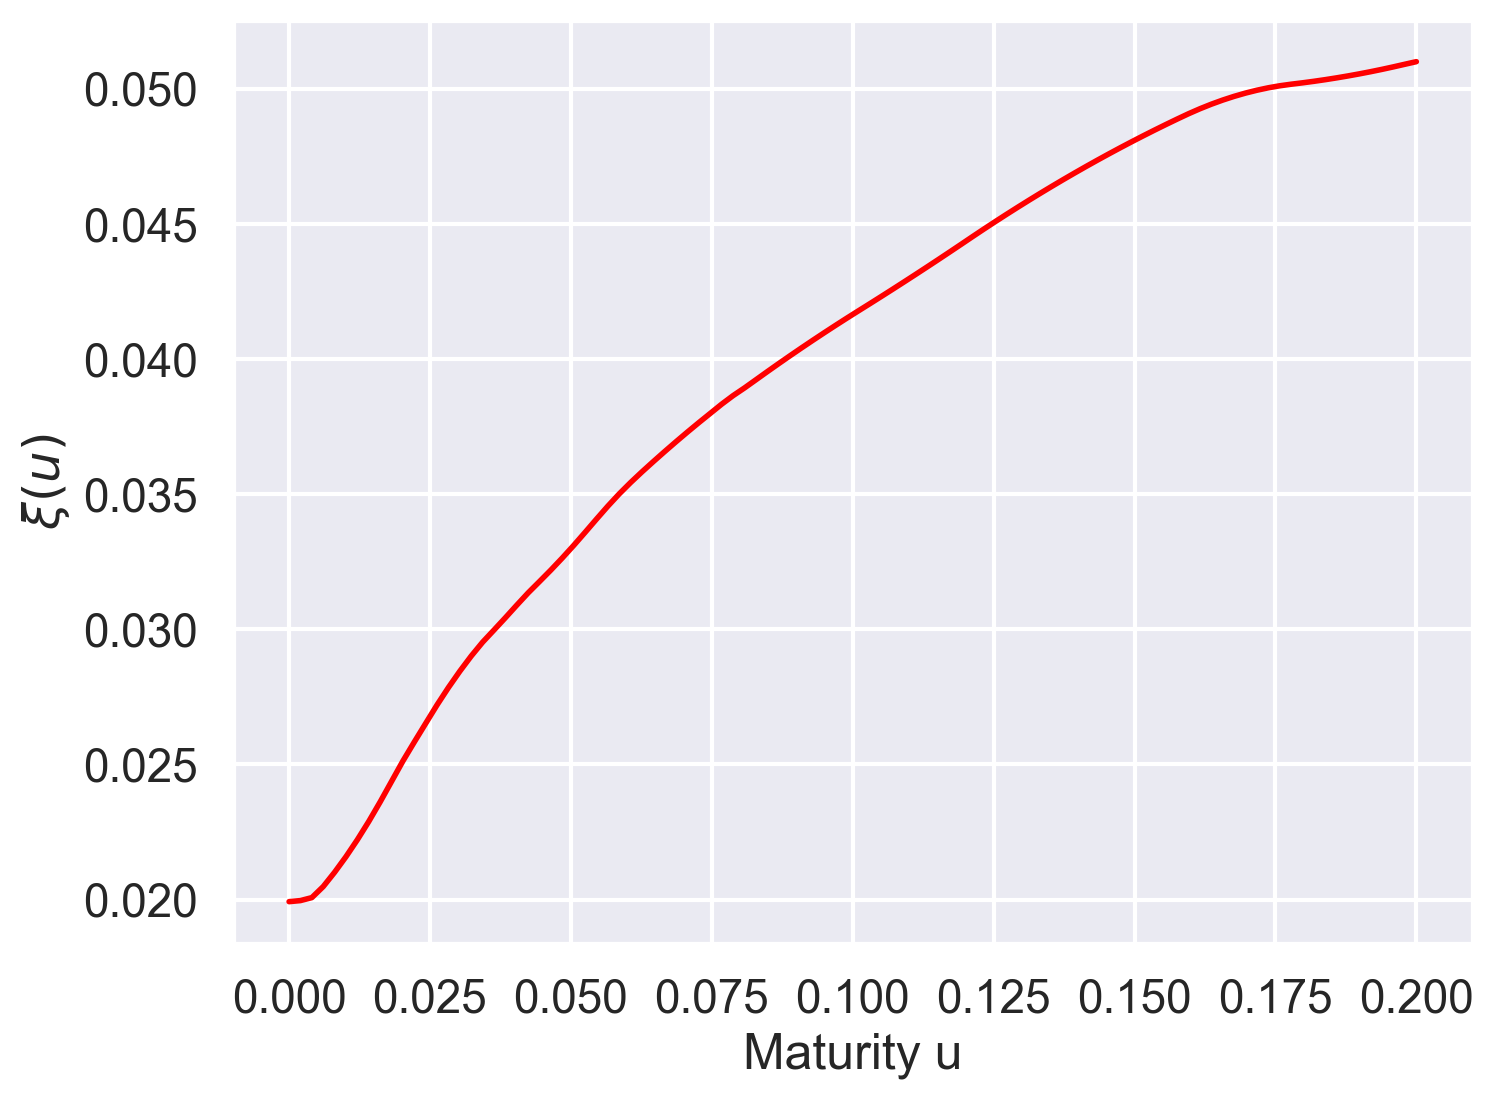

In [6]:
u = np.linspace(0, 0.2, 100)
fig, ax = plt.subplots()
ax.plot(u, xi_smooth(u), color="red", linewidth=2)
ax.set_xlabel("Maturity u")
ax.set_ylabel(r"$\xi(u)$")
plt.show()

# $y_t(u)$ from $\xi_t(u)$

$$ y_t(u)^2= \xi_t(u) - c - \int_t^u\,\xi_t(s)\,\kappa (u-s)^2\,ds. $$

Integration is performed using Gauss-Jacobi quadrature.


In [7]:
qrh = QuadraticRoughHeston(**params0, xi0=xi_smooth)

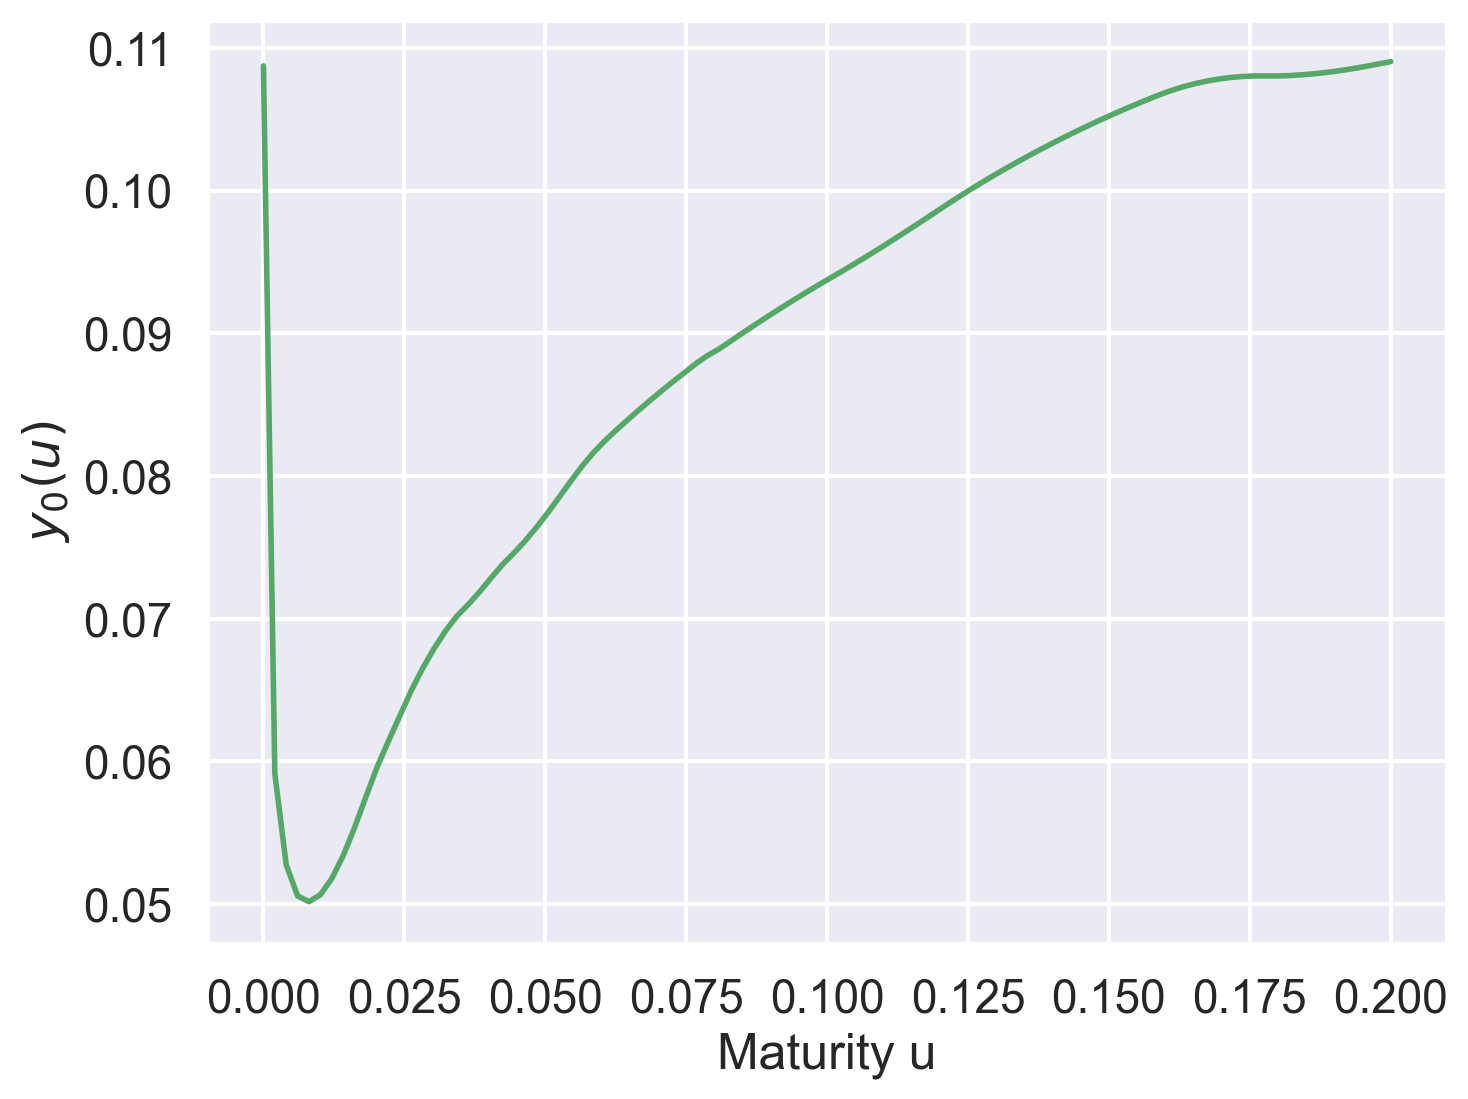

In [8]:
u = np.linspace(0, 0.2, 100)
fig, ax = plt.subplots()
ax.plot(u, qrh.y0(u), color="g", linewidth=2)
ax.set_xlabel("Maturity u")
ax.set_ylabel(r"$y_0(u)$")
plt.show()

### Sanity check for a constant forward variance curve $\xi_0(u) = \xi$. 


From the definition, we have that
$$
    \begin{align*}
        y_0(u)^2 &= \xi_0(u) - c - \int_0^u\,\xi_0(s)\,\kappa (u-s)^2\,ds \\
               &= \xi - c - \xi u \int_0^1 \, \kappa (u s)^2\,ds \\
    \end{align*}
$$

In [10]:
def xi0_flat(u):
    return 0.2**2 + 0 * u


params = {"al": 0.78, "lam": 2.0, "nu": 0.572, "c": 8.1e-3}

qrh_flat = QuadraticRoughHeston(**params, xi0=xi0_flat)

In [11]:
def integral_kappa2(u):
    return u * integrate.quad_vec(lambda s: qrh_flat.kernel(u * s) ** 2, 0, 1)[0]

In [12]:
tab_u = np.linspace(1e-4, 0.8, 101)


y0_flat_u = (xi0_flat(0.0) - qrh_flat.c - xi0_flat(0.0) * integral_kappa2(tab_u)) ** 0.5

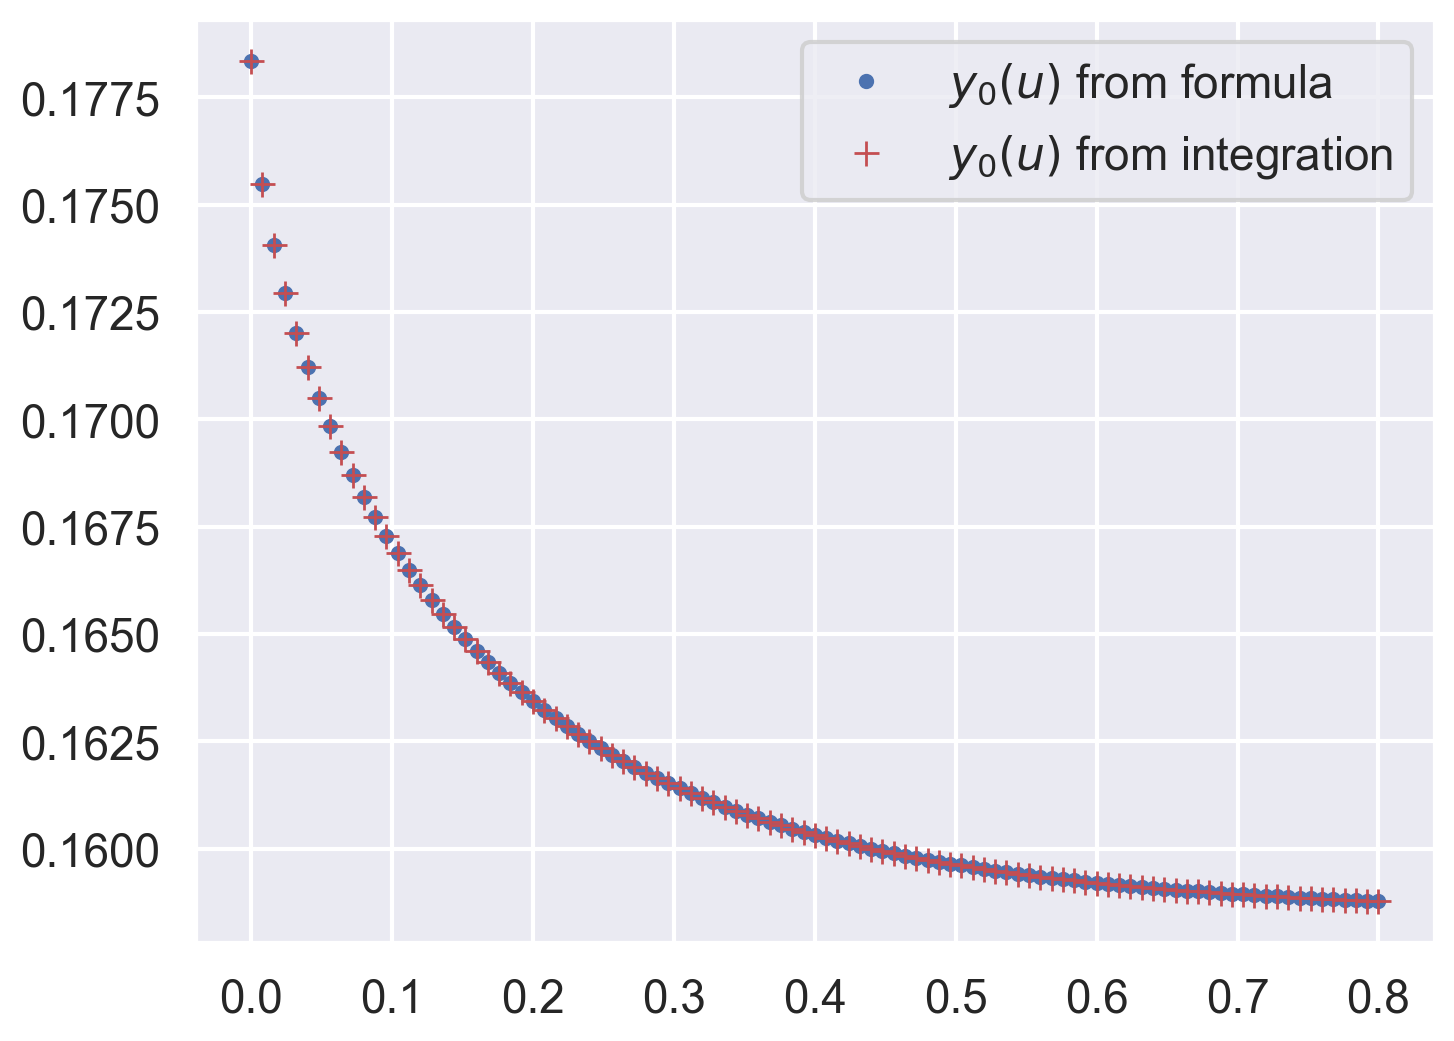

In [13]:
fig, ax = plt.subplots()
ax.plot(tab_u, y0_flat_u, "b.", label=r"$y_0(u)$ from formula")
ax.plot(tab_u, qrh_flat.y0(tab_u), "+r", label=r"$y_0(u)$ from integration")
ax.legend()
plt.show()

# Choose expiries


In this particular case, we choose identical SPX and VIX expiries.

Here, expiries are $7,14,20,28$ days.


In [9]:
spx_expiries_days = [7, 14, 20, 28]
vix_expiries_days = [7, 14, 20, 28]
spx_expiries = np.array(spx_expiries_days) / 365.25
vix_expiries = np.array(vix_expiries_days) / 365.25

# Run simulations


In [10]:
# paths = 1 * 10**5
# steps = 100

paths = 2 * 10**5
steps = 300

In [12]:
res = qrh.simulate(paths=paths, steps=steps, spx_expiries=spx_expiries, output="all")

In [15]:
res["spx"]

{np.float64(0.019164955509924708): {'X': array([-0.00236121, -0.00577736, -0.05361996, ...,  0.00969613,
         -0.04434402,  0.00307523], shape=(200000,)),
  'vix': array([0.1842683 , 0.19025492, 0.22629791, ..., 0.17283895, 0.25900518,
         0.17331975], shape=(200000,)),
  'v': array([0.01402526, 0.02866656, 0.0134558 , ..., 0.0081031 , 0.12063397,
         0.00850136], shape=(200000,)),
  'w': array([0.00030889, 0.00045212, 0.0018385 , ..., 0.00031886, 0.00092896,
         0.00048997], shape=(200000,)),
  'chi': array([[ 2.08791039e-03,  8.49342057e-04, -7.70348194e-04, ...,
           4.40559081e-04,  1.20875000e-03, -1.02662739e-03],
         [ 5.02954175e-05, -5.10122523e-04,  1.21152795e-03, ...,
           1.46715199e-03, -1.42316629e-03, -6.81395722e-04],
         [-4.47834580e-04, -3.90395455e-04, -8.91398182e-04, ...,
           1.28654189e-03,  7.42415740e-04, -1.23036447e-03],
         ...,
         [-2.47169792e-07,  1.46617947e-03,  1.14149960e-03, ...,
           

In [16]:
# save Monte Carlo variance V_T for each expiry
tab_v_mc = np.array(
    [res["spx"][spx_expiries[i]]["v"] for i in range(len(spx_expiries))]
)

Recall that $V_t = Y_t^2 + c$ where $Y_t = y_t(u) + \int_t^u \kappa(u-s) \sqrt{V_s} dW_s$

We want to compute $\mathbb{E}[Y_t^2]$ and $\mathbb{E}[Y_t^4]$.

In [17]:
np.mean(tab_v_mc - qrh.c, axis=1)

array([0.01724306, 0.02320738, 0.02712192, 0.0315553 ])

In [18]:
# TODO: compare with closed-form for E[Y_t^2] and normal approx for E[Y_t^4]

# SPX smiles


In [19]:
# Monte Carlo SPX smiles
spx_mc_matrix = np.array([np.exp(res["spx"][exp]["X"]) for exp in spx_expiries])
# subset market data for selected expiries
df_spx_sub = (
    df_spx[df_spx["Texp_days"].isin(spx_expiries_days)].dropna().reset_index(drop=True)
)

Plot

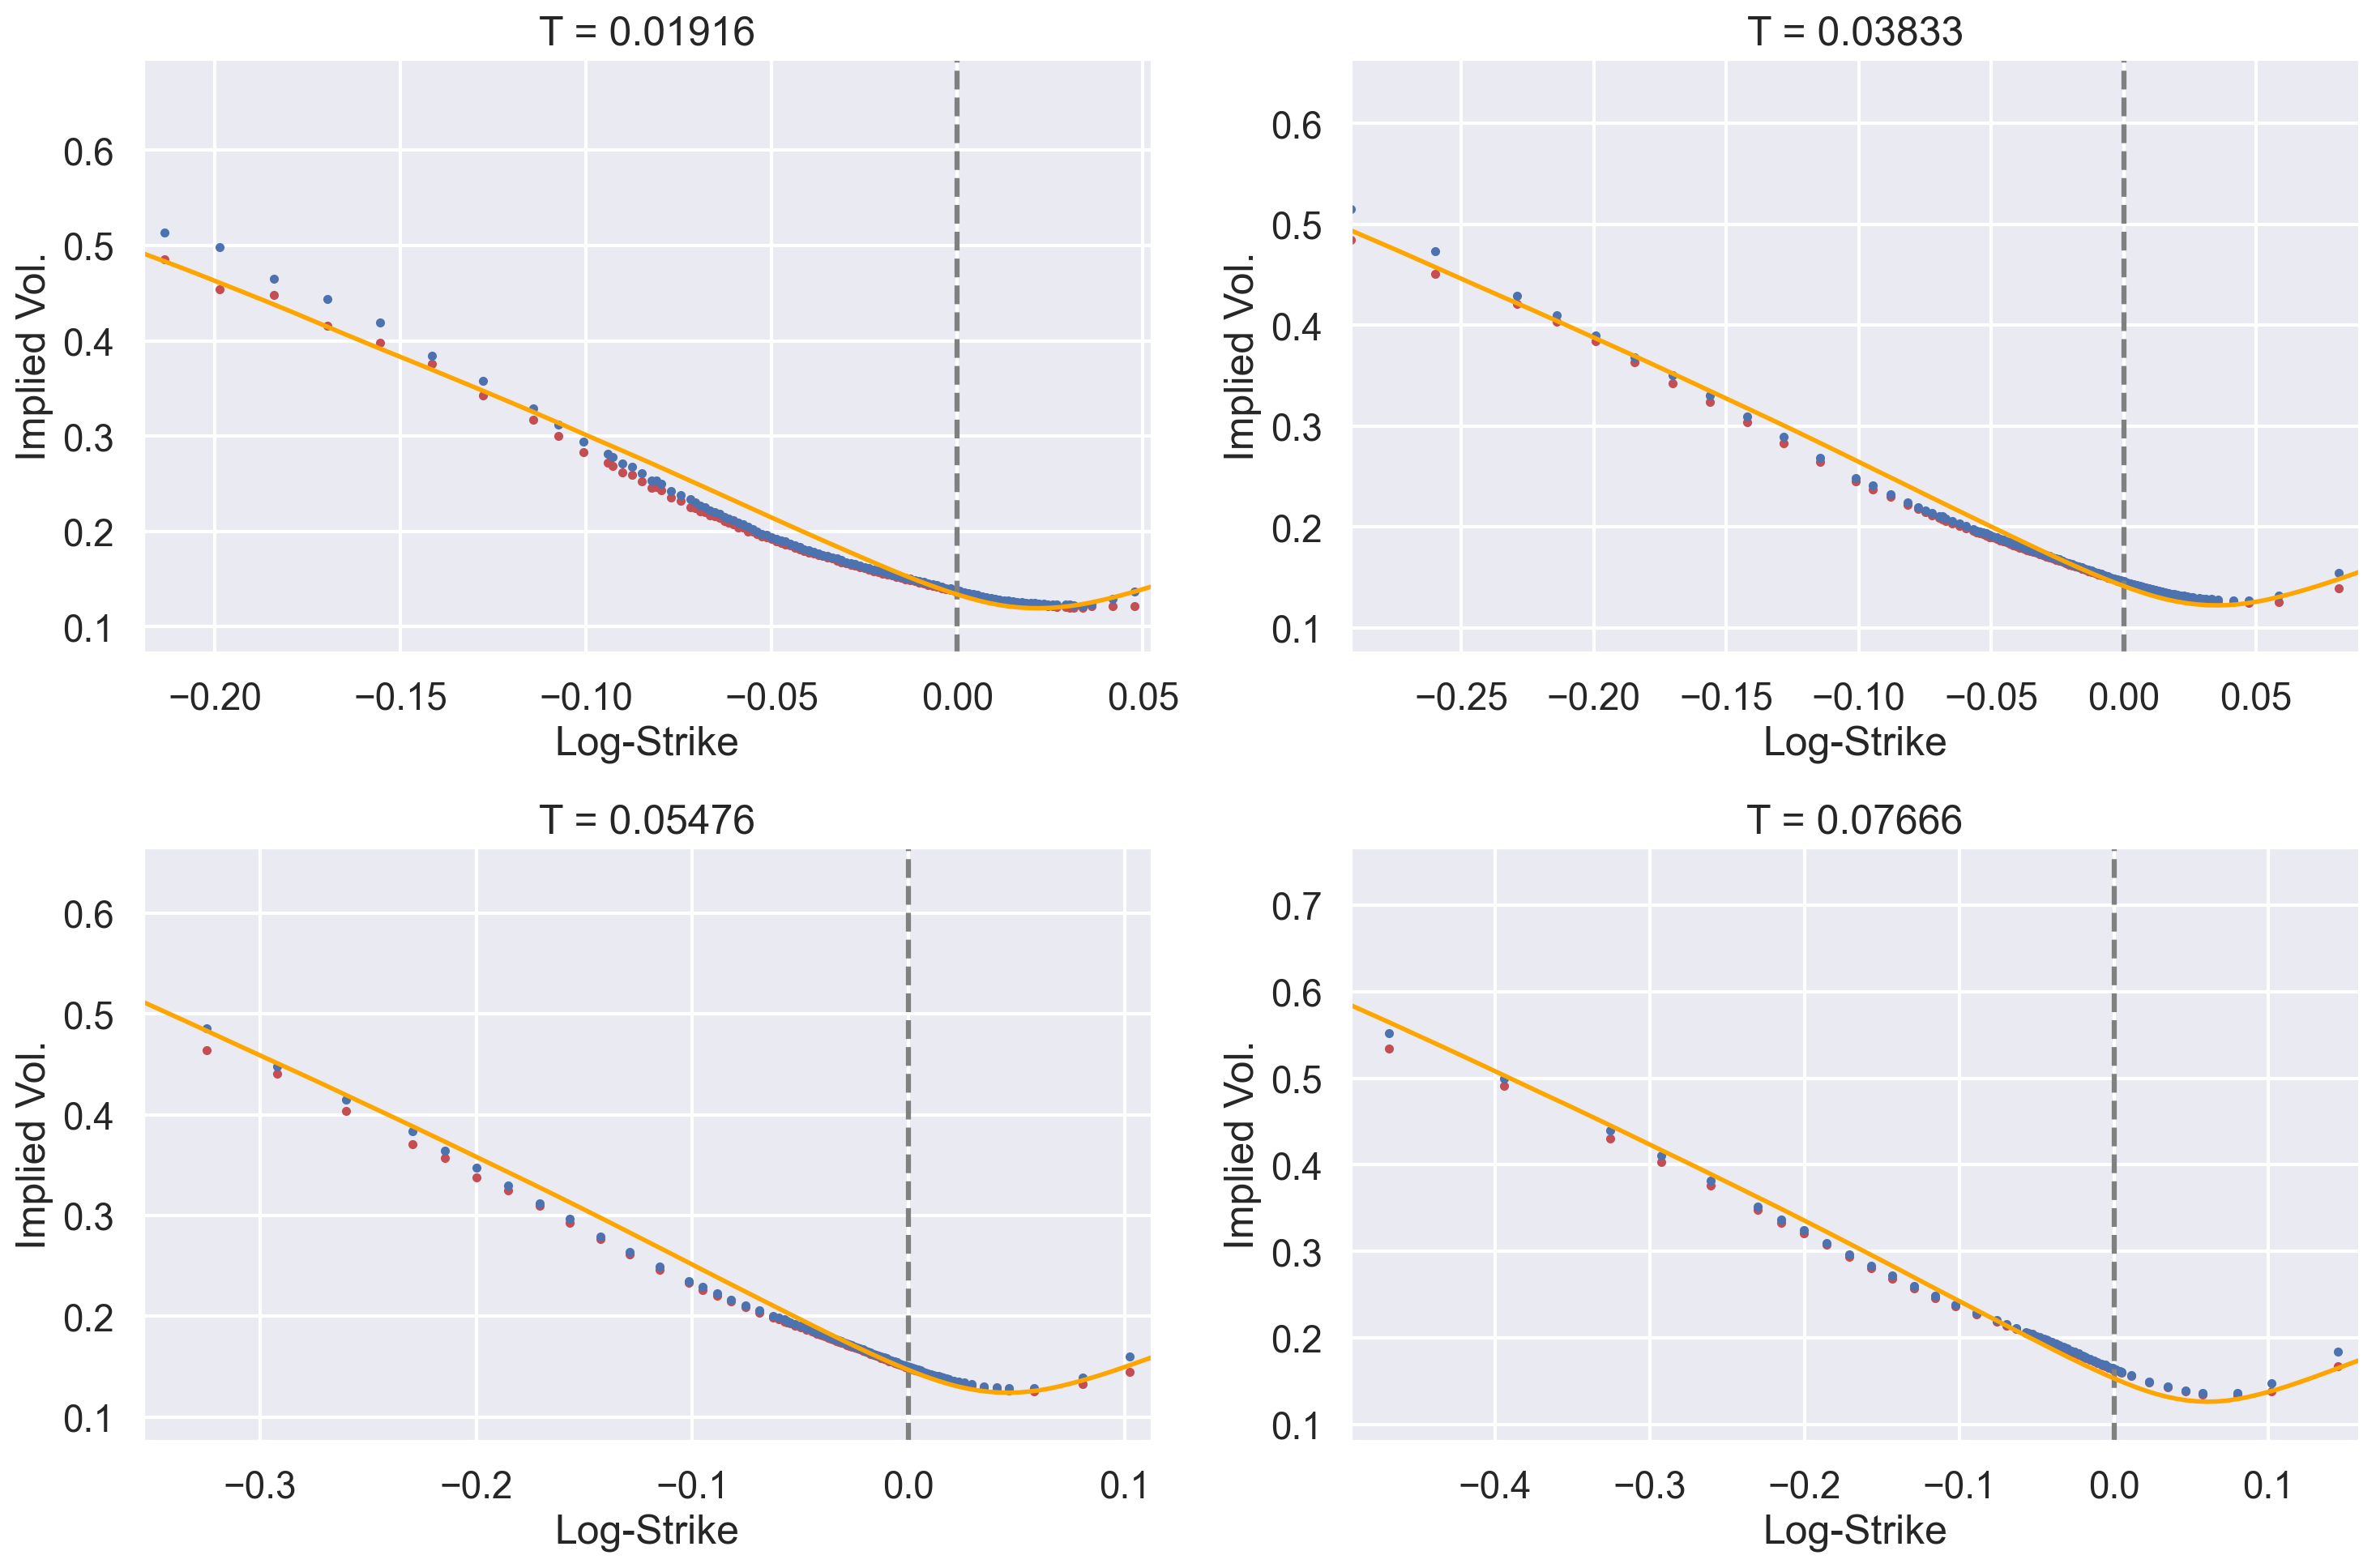

In [20]:
plot_spx = plot_ivols_mc(ivol_data=df_spx_sub, mc_matrix=spx_mc_matrix)

# VIX smiles


In [22]:
# Monte Carlo VIX smiles
vix_mc_matrix = np.array([res["spx"][exp]["vix"] for exp in vix_expiries])
# subset market data for selected expiries
df_vix_sub = (
    df_vix[df_vix["Texp_days"].isin(vix_expiries_days)].dropna().reset_index(drop=True)
)

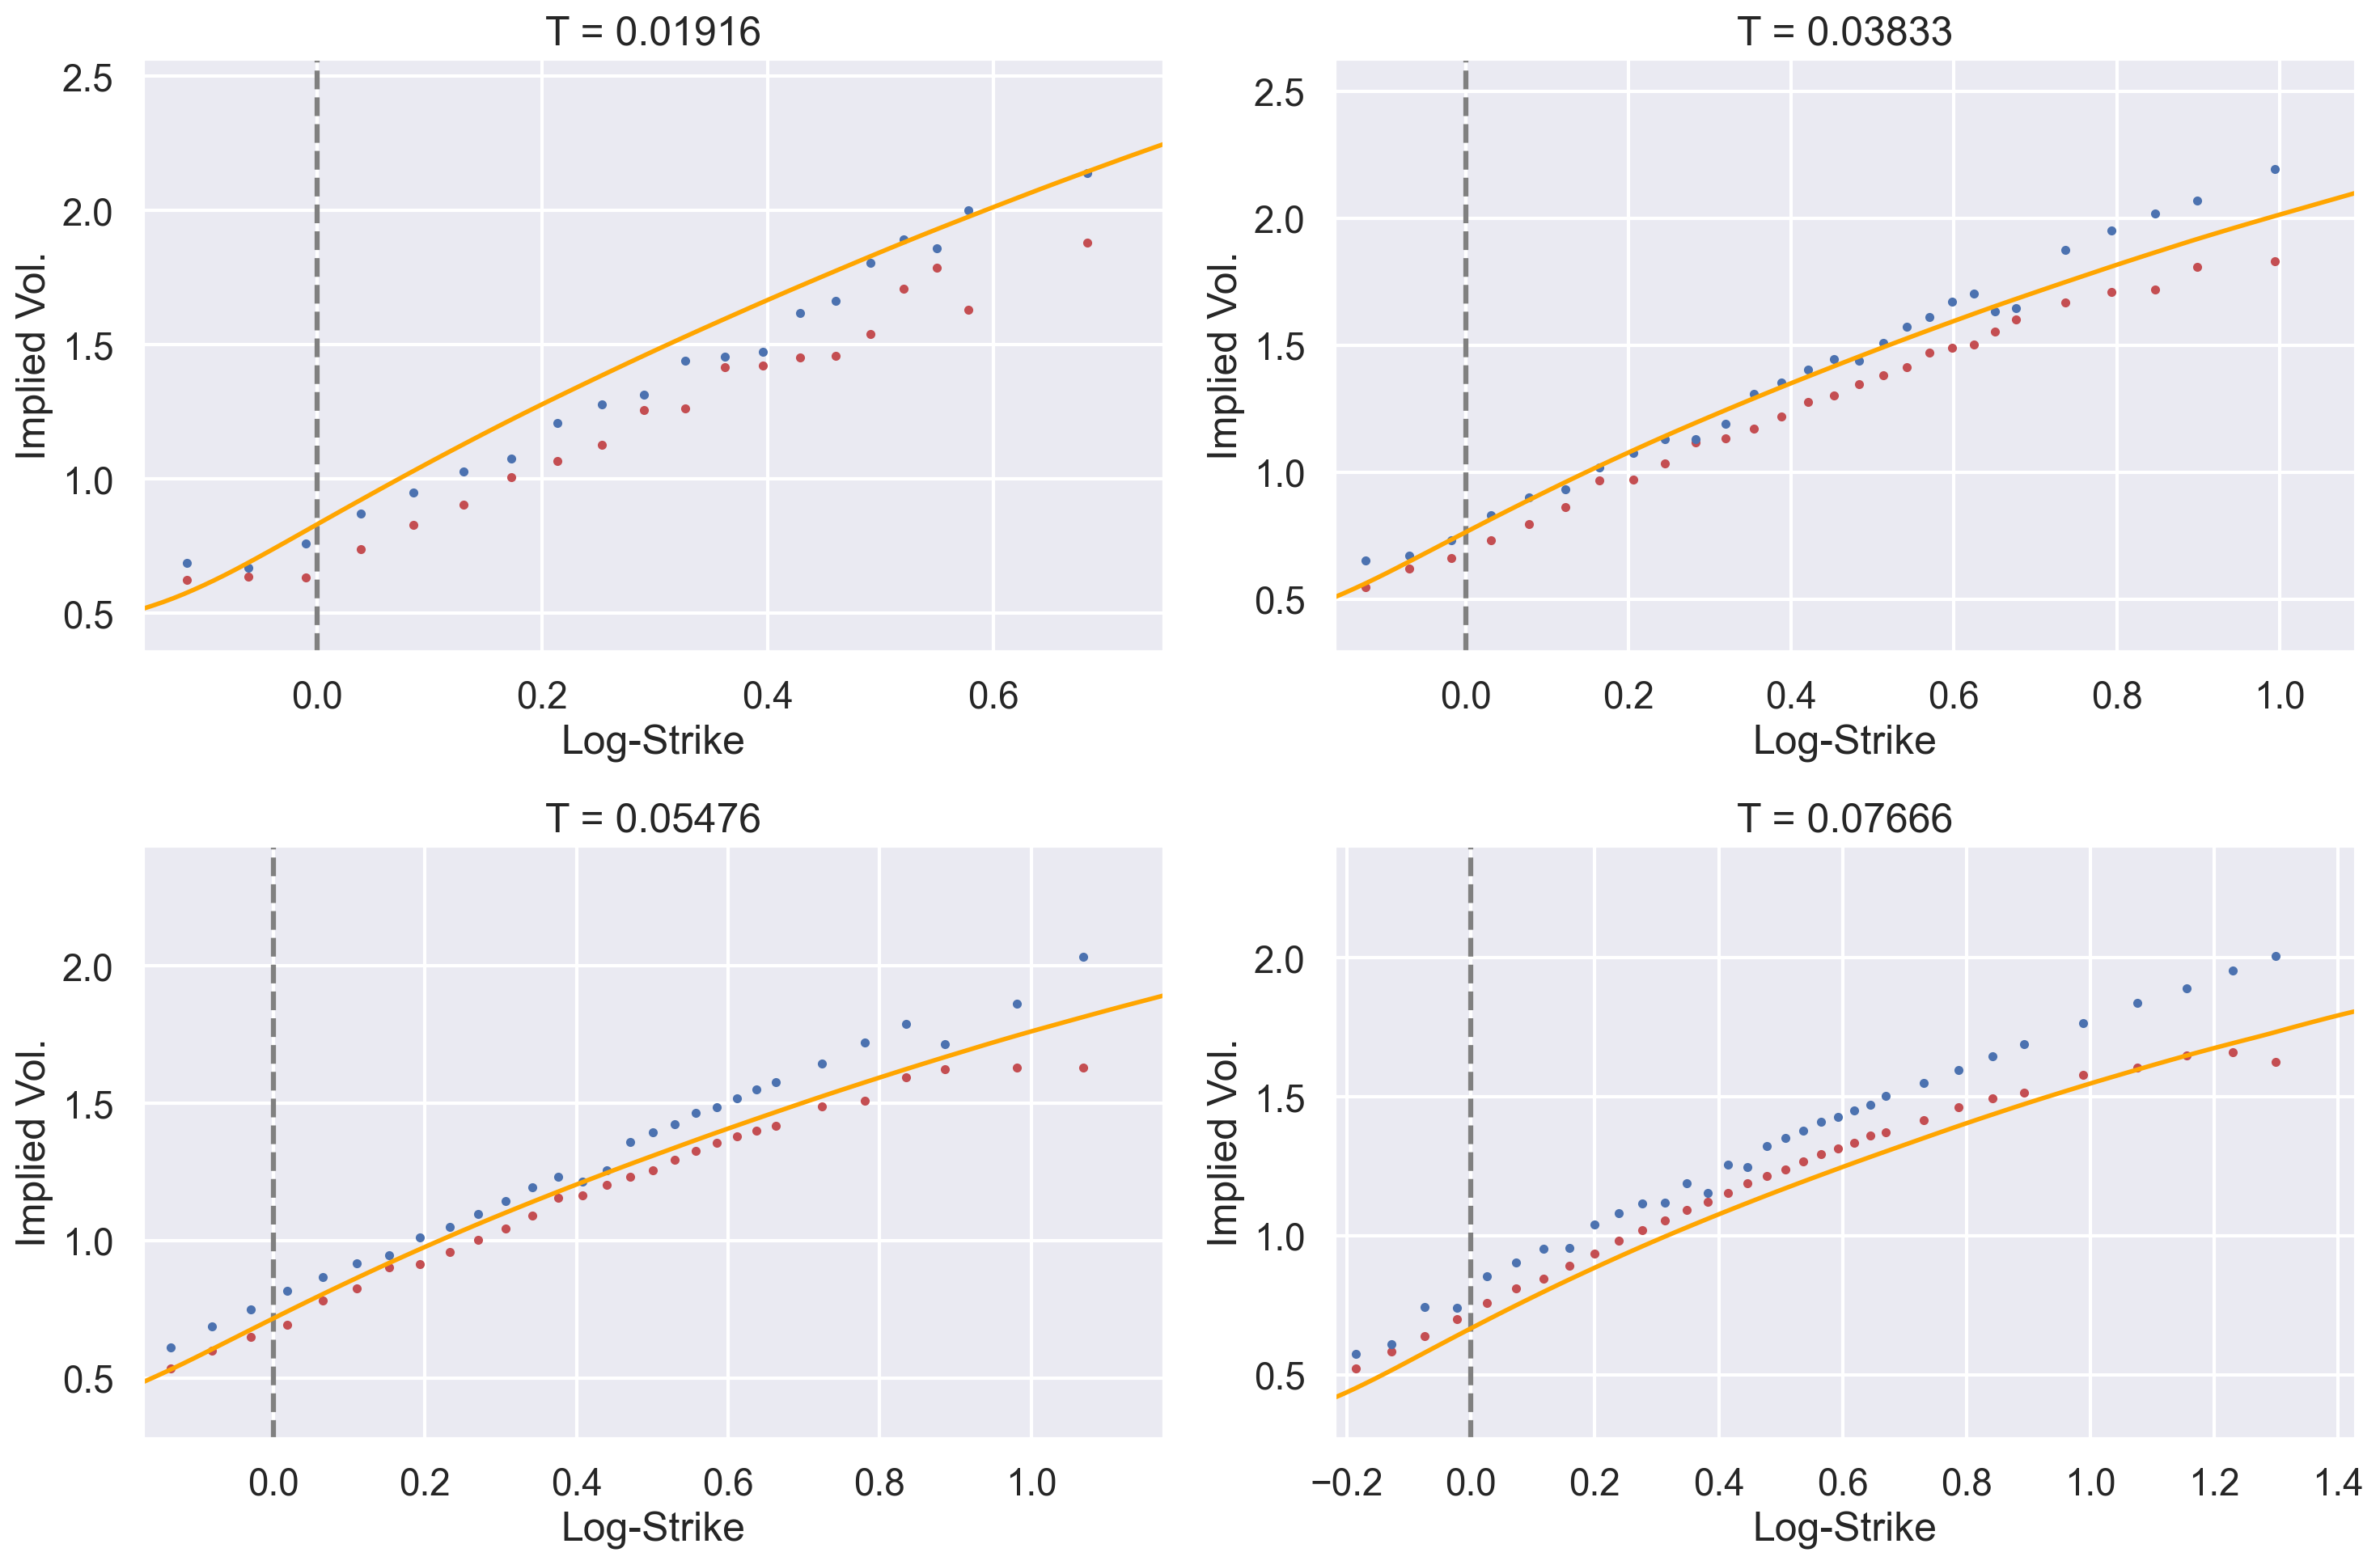

In [23]:
plot_vix = plot_ivols_mc(ivol_data=df_vix_sub, mc_matrix=vix_mc_matrix)

# We try to use more maturities for the SPX and VIX smiles

List available spx maturities in days

In [ ]:
spx_mkt_days = df_spx["Texp_days"].unique()
print(spx_mkt_days)

[   1    2    6    7    8    9   12   13   14   15   16   19   20   21
   22   23   26   27   28   29   30   33   37   44   58   65   72   93
  105  121  135  156  166  184  212  226  247  275  303  317  338  366
  394  492  674 1038 1402 1766]


List available vix maturities in days

In [ ]:
vix_mkt_days = df_vix["Texp_days"].unique()
print(vix_mkt_days)

[  7  14  20  28  35  63  91 126 154 182 217 245]


Pick specific list of expiries for SPX and VIX

In [67]:
spx_expiries_days = spx_mkt_days
spx_expiries = np.array(spx_expiries_days) / 365.25

In [68]:
vix_expiries_days = vix_mkt_days
vix_expiries = np.array(vix_expiries_days) / 365.25

Simulate

In [69]:
res = qrh.simulate(
    paths=paths,
    steps=steps,
    spx_expiries=spx_expiries,
    vix_expiries=vix_expiries,
    output="all",
    nvix=15,
)

Simulating expiry = 0.0027
Simulating expiry = 0.0055
Simulating expiry = 0.0164
Simulating expiry = 0.0192
Simulating expiry = 0.0219
Simulating expiry = 0.0246
Simulating expiry = 0.0329
Simulating expiry = 0.0356
Simulating expiry = 0.0383
Simulating expiry = 0.0411
Simulating expiry = 0.0438
Simulating expiry = 0.0520
Simulating expiry = 0.0548
Simulating expiry = 0.0575
Simulating expiry = 0.0602
Simulating expiry = 0.0630
Simulating expiry = 0.0712
Simulating expiry = 0.0739
Simulating expiry = 0.0767
Simulating expiry = 0.0794
Simulating expiry = 0.0821
Simulating expiry = 0.0903
Simulating expiry = 0.1013
Simulating expiry = 0.1205
Simulating expiry = 0.1588
Simulating expiry = 0.1780
Simulating expiry = 0.1971
Simulating expiry = 0.2546
Simulating expiry = 0.2875
Simulating expiry = 0.3313
Simulating expiry = 0.3696
Simulating expiry = 0.4271
Simulating expiry = 0.4545
Simulating expiry = 0.5038
Simulating expiry = 0.5804
Simulating expiry = 0.6188
Simulating expiry = 0.6762
S

: 

In [63]:
spx_mc_matrix = np.array([np.exp(res["spx"][exp]["X"]) for exp in spx_expiries])
df_spx_sub = (
    df_spx[df_spx["Texp_days"].isin(spx_expiries_days)].dropna().reset_index(drop=True)
)

In [64]:
vix_mc_matrix = np.array([res["vix"][exp]["vix"] for exp in vix_expiries])
df_vix_sub = (
    df_vix[df_vix["Texp_days"].isin(vix_expiries_days)].dropna().reset_index(drop=True)
)

Plot

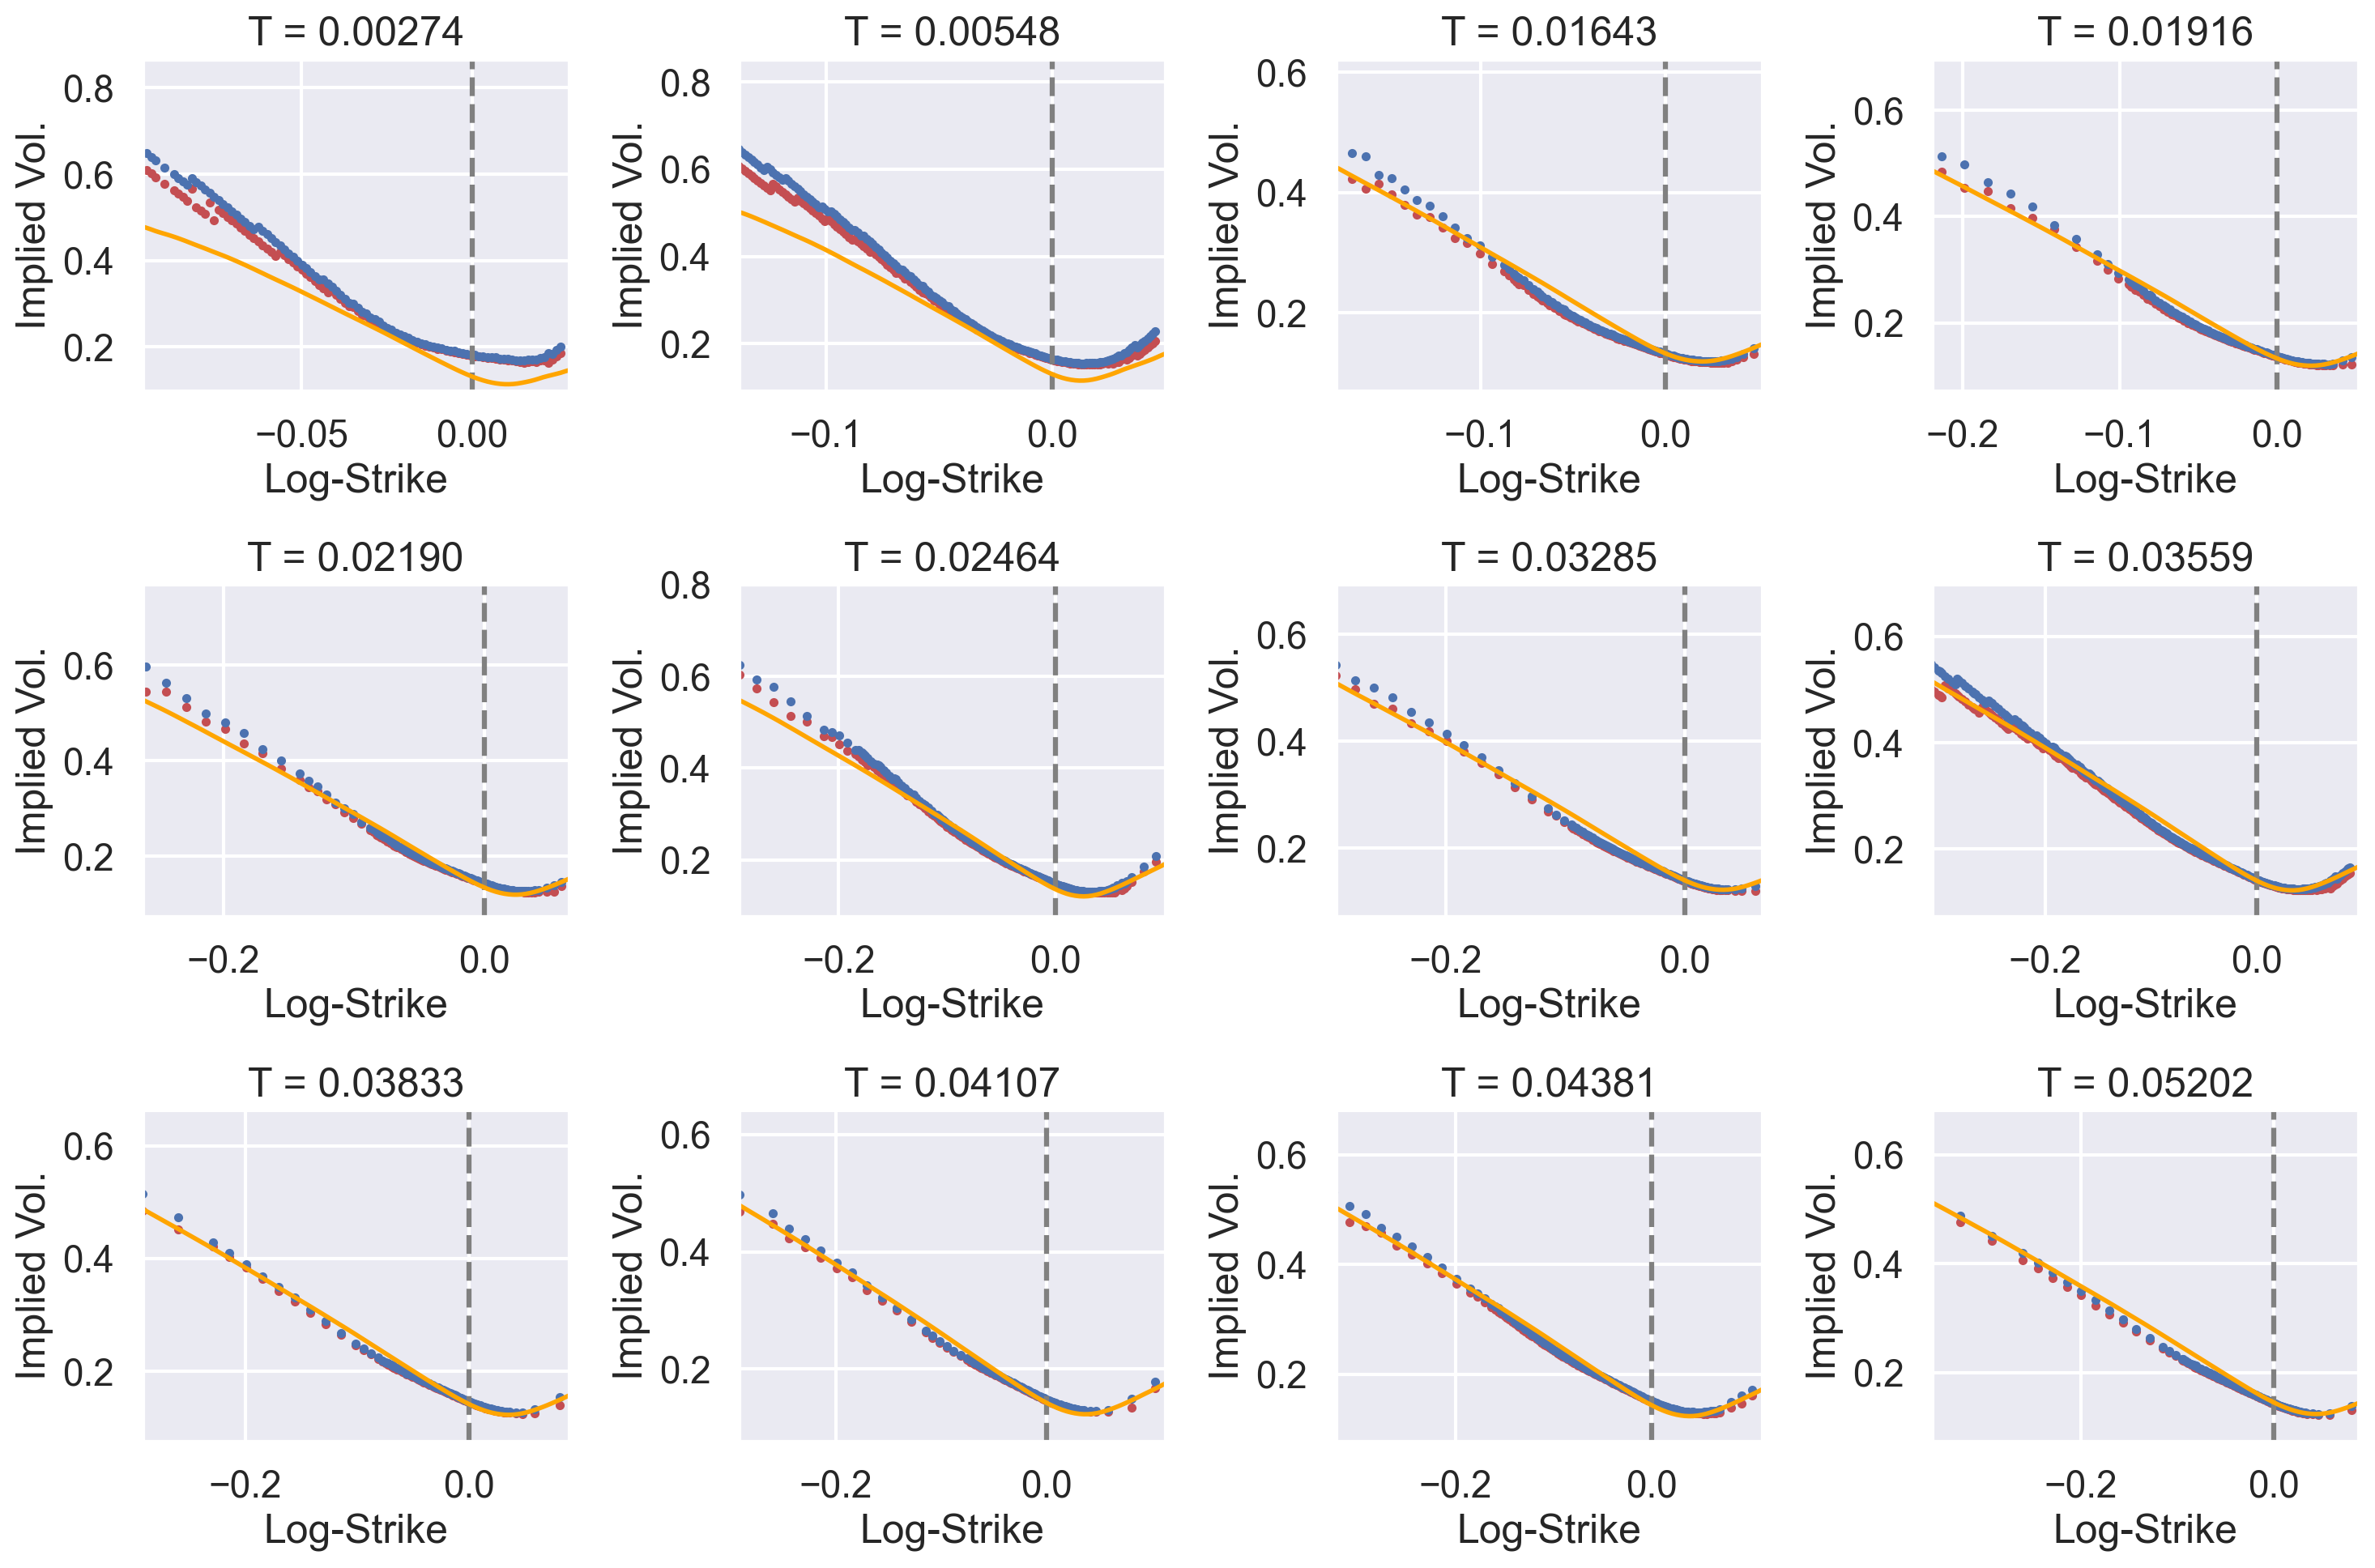

In [65]:
plot_spx = plot_ivols_mc(ivol_data=df_spx_sub, mc_matrix=spx_mc_matrix)

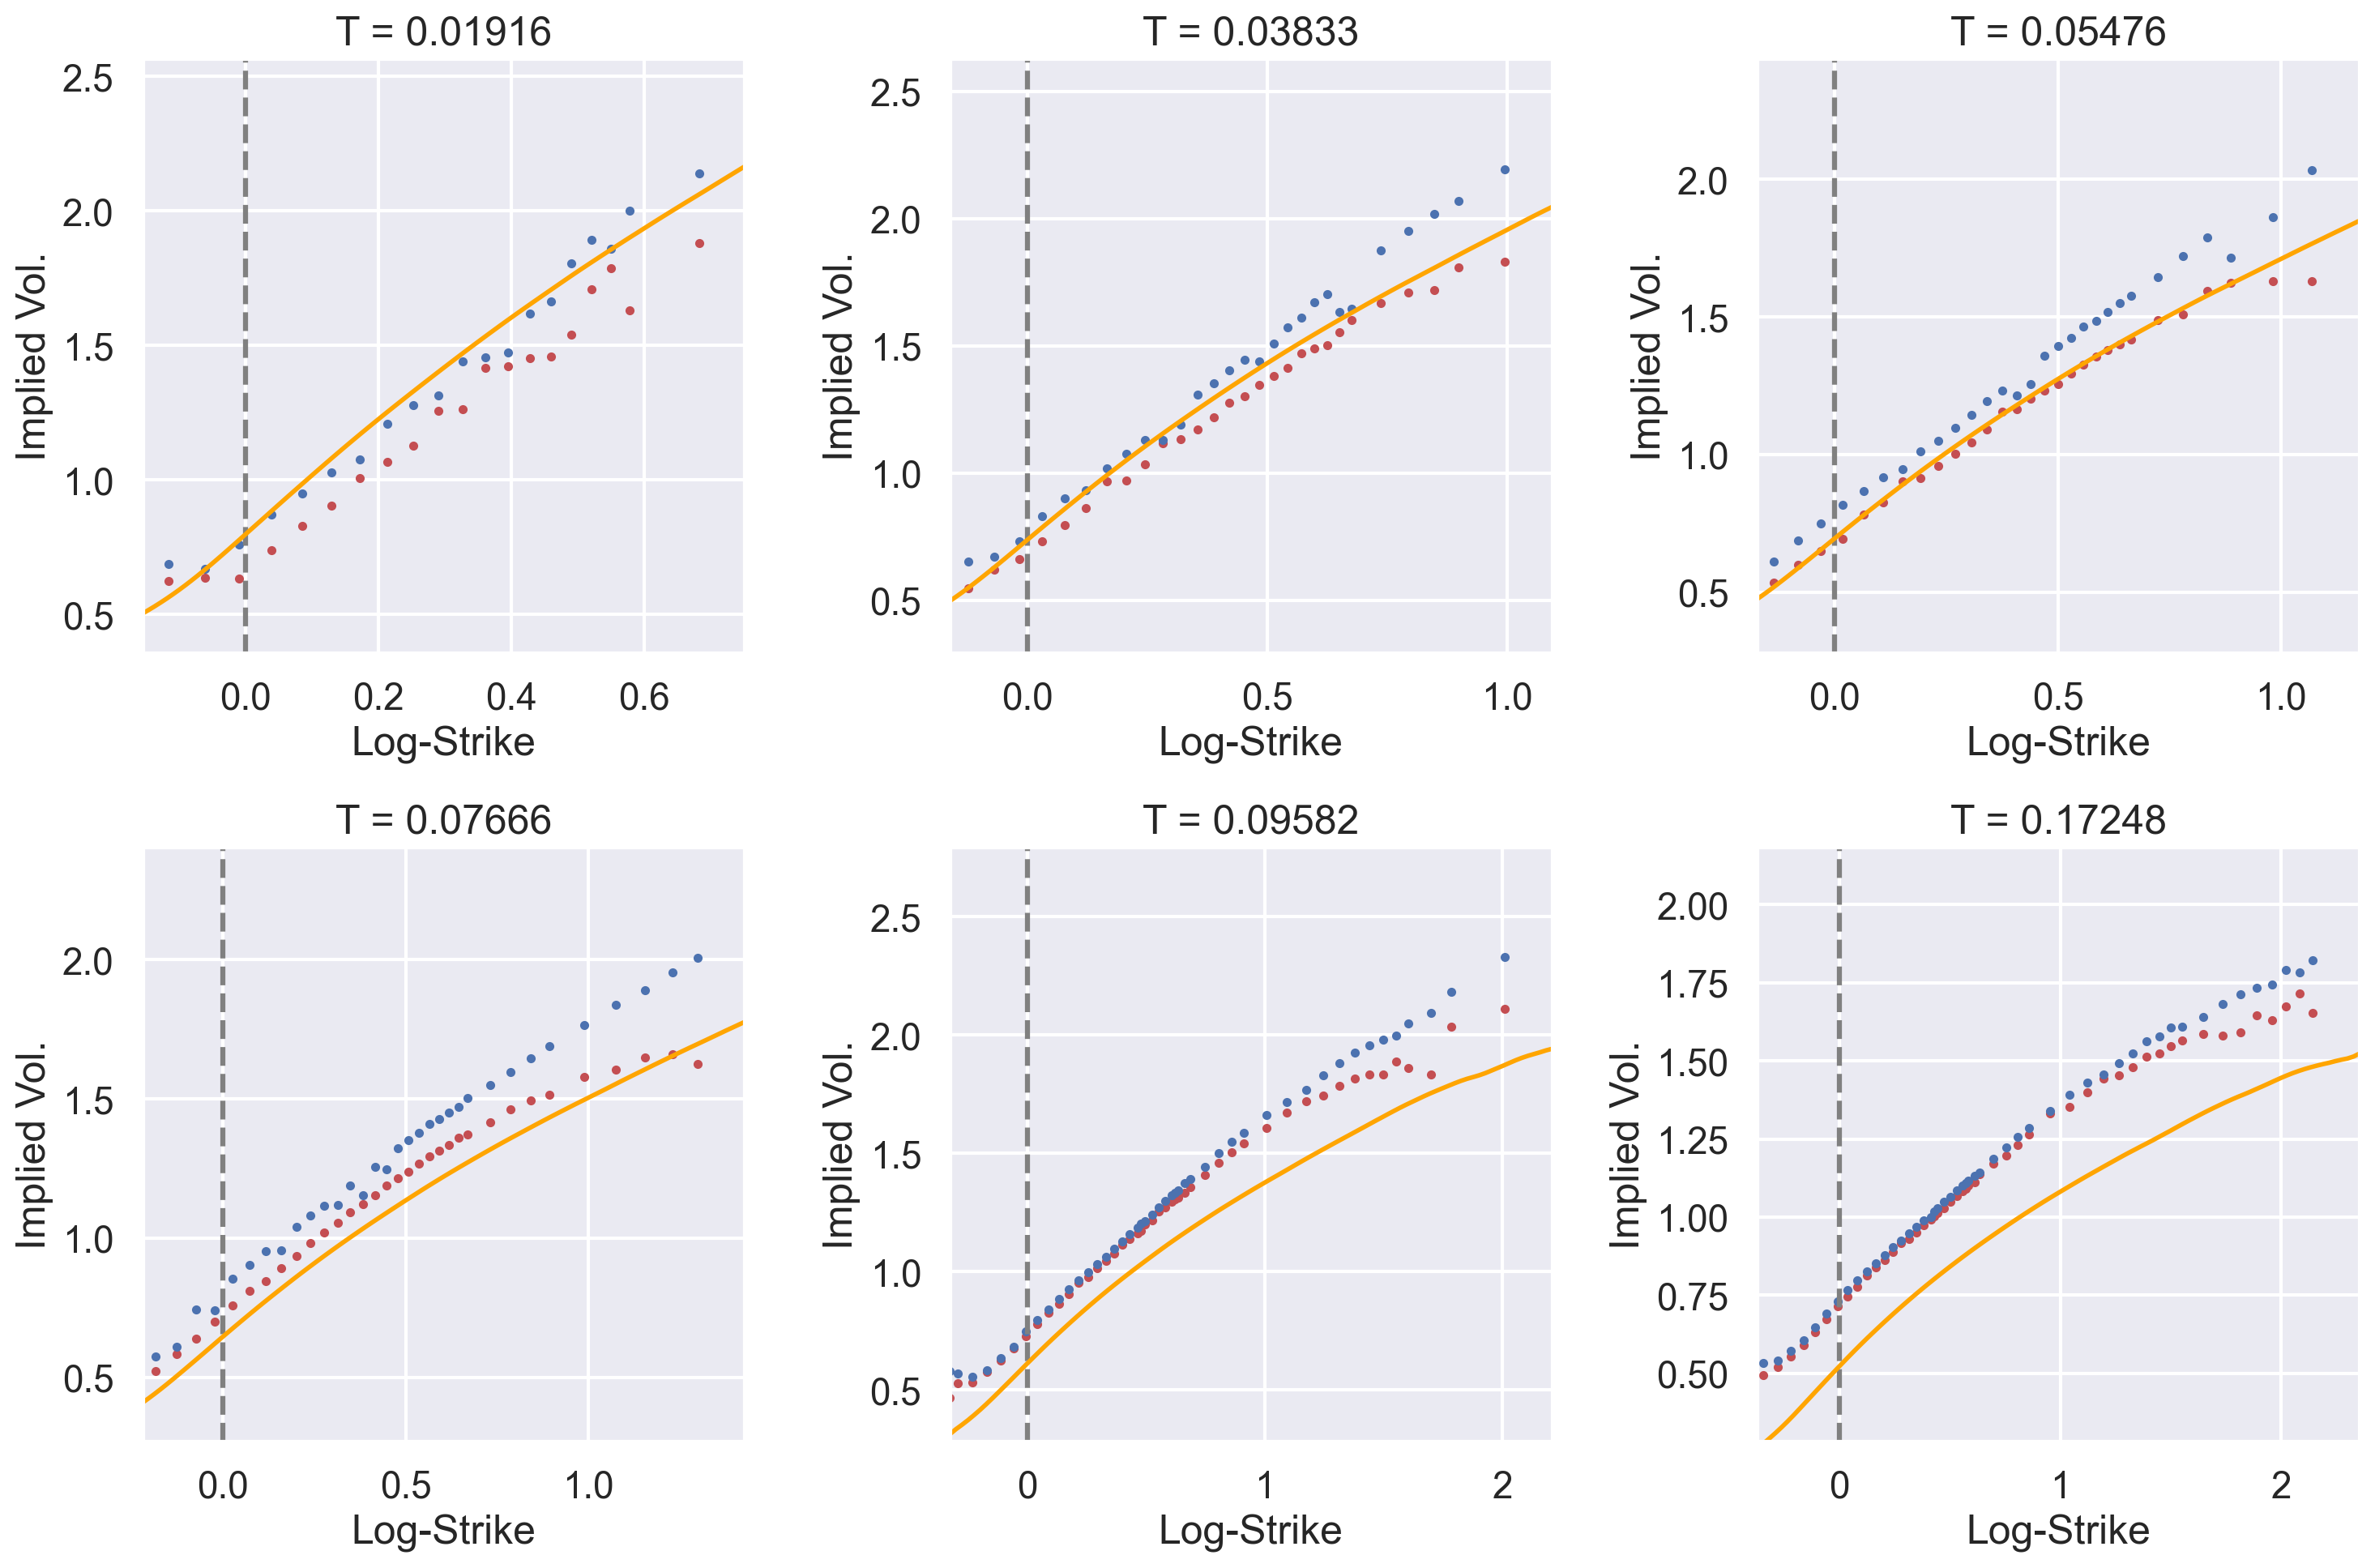

In [66]:
plot_vix = plot_ivols_mc(ivol_data=df_vix_sub, mc_matrix=vix_mc_matrix)